# DataCo Supply Chain — Cleaning, Late-Delivery Prediction & RFM Segmentation

End-to-end pipeline:

1. **Load** the raw `.xlsx`
2. **Clean** — fix Excel-corrupted dates, broken rows, redundant / masked / constant columns
3. **EDA** — the few patterns that matter for modeling
4. **Late-delivery prediction** — leak-free, order-level, time-based split
   - Baseline 0: shipping-mode lookup rule
   - Baseline 1: Logistic Regression
   - Gradient-boosted trees (LightGBM if installed, otherwise scikit-learn `HistGradientBoostingClassifier`)
   - Calibration check + evaluation on the post-Oct-2017 regime (distribution shift)
5. **Customer segmentation** — RFM features + K-means

> Put `DataCoSupplyChainDataset.xlsx` in the same folder as this notebook (or edit `DATA_PATH`).
> The first load takes 1–3 minutes; the notebook caches a pickle so re-runs are fast.

In [2]:
import os, warnings, datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, roc_auc_score, f1_score, brier_score_loss,
                             log_loss, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

try:
    import lightgbm as lgb
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})

RANDOM_STATE = 42
DATA_PATH  = "DataCoSupplyChainDataset.xlsx"
CACHE_PATH = "datacos_raw.pkl"
print("LightGBM available:", HAS_LGBM)

LightGBM available: True


## 1. Load the raw Excel file

In [3]:
if os.path.exists(CACHE_PATH):
    raw = pd.read_pickle(CACHE_PATH)
else:
    raw = pd.read_excel(DATA_PATH, engine="openpyxl")   # slow: ~180k rows x 53 cols
    raw.to_pickle(CACHE_PATH)

print(raw.shape)
raw.head(3)

(180519, 53)


,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Email,Customer Fname,Customer Id,Customer Lname,Customer Password,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Description,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Cally,20755,Holloway,XXXXXXXXX,Consumer,PR,5365 Noble Nectar Island,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,1/31/2018 22:56,77202,1360,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,2018-03-02 22:56:00,Standard Class
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,Puerto Rico,XXXXXXXXX,Irene,19492,Luna,XXXXXXXXX,Consumer,PR,2679 Rustic Loop,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,1/13/2018 12:27,75939,1360,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/18/2018 12:27,Standard Class
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,EE. UU.,XXXXXXXXX,Gillian,19491,Maldonado,XXXXXXXXX,Consumer,CA,8510 Round Bear Gate,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,1/13/2018 12:06,75938,1360,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,NaN,1360,73,NaN,http://images.acmesports.sports/Smart+watch,Smart watch,327.75,0,1/17/2018 12:06,Standard Class


In [4]:
# Profile: nulls, cardinality and the Python types actually stored in each column
profile = pd.DataFrame({
    "nulls": raw.isna().sum(),
    "null_%": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
    "stored_types": [raw[c].map(lambda v: type(v).__name__).value_counts().to_dict() for c in raw.columns],
})
profile

,nulls,null_%,n_unique,stored_types
Type,0,0.0,4,{'str': 180519}
Days for shipping (real),0,0.0,7,{'int': 180519}
Days for shipment (scheduled),0,0.0,4,{'int': 180519}
Benefit per order,0,0.0,21998,{'float': 180519}
Sales per customer,0,0.0,2927,{'float': 180519}
Delivery Status,0,0.0,4,{'str': 180519}
Late_delivery_risk,0,0.0,2,{'int': 180519}
Category Id,0,0.0,51,{'int': 180519}
Category Name,0,0.0,50,{'str': 180519}
Customer City,0,0.0,563,{'str': 180519}


## 2. Data cleaning

Issues found in profiling and what we do about each:

| Issue | Fix |
|---|---|
| **Both date columns hold mixed types**: ~40% are real Excel dates with **day and month swapped** (e.g. 3 Feb 2018 stored as 2 Mar 2018), the rest are `M/D/YYYY H:MM` strings | Swap day↔month for datetime cells, parse strings explicitly, then verify against `Days for shipping (real)` |
| 3 rows are shifted by one column (`Customer City`='CA', state = a zip code, zipcode null) | Shift values back into place |
| Trailing whitespace in text (e.g. `'Smart watch '`) | Strip all string columns |
| `Customer Country` uses Spanish `EE. UU.` | Map to `United States` |
| Masked / PII columns (email, password, names, street) | Drop |
| Constant or empty columns (`Product Status`, `Product Description`) and image URLs | Drop |
| Exact duplicate columns (5 pairs) | Keep one of each |
| `Order Zipcode` 86% null | Drop |
| `Category Id` has 51 ids for 50 names (Electronics twice) | Use `Category Name` |
| Catalog / volume **regime change from Oct 2017** | Flag with `post_shift`; keep out of training |

In [5]:
df = raw.copy()

# --- 2.1 strip whitespace in all text columns -------------------------------
for c in df.columns:
    if df[c].dtype == object:
        df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)

# --- 2.2 fix the date columns ------------------------------------------------
def fix_date(v):
    # Cells Excel auto-converted were read D/M instead of M/D, so swap month and day back.
    if isinstance(v, (dt.datetime, pd.Timestamp)):
        return pd.Timestamp(year=v.year, month=v.day, day=v.month, hour=v.hour, minute=v.minute)
    return pd.to_datetime(v, format="%m/%d/%Y %H:%M")

df["order_date"] = df["order date (DateOrders)"].map(fix_date)
df["ship_date"]  = df["shipping date (DateOrders)"].map(fix_date)

# Verify: (ship - order) in days should equal 'Days for shipping (real)'
diff = (df["ship_date"] - df["order_date"]).dt.days
match = diff == df["Days for shipping (real)"]
print(f"Date reconciliation: {match.mean():.2%} of rows match 'Days for shipping (real)'")
print("Mismatches by shipping mode / recorded days:")
print(pd.crosstab(df.loc[~match, "Shipping Mode"], df.loc[~match, "Days for shipping (real)"]))
# All mismatches are Same Day orders where ship timestamp == order timestamp but 1 day is recorded.
# That's a source inconsistency, not a parsing error -> keep and note.
print("Order date range:", df["order_date"].min(), "->", df["order_date"].max())

Date reconciliation: 97.42% of rows match 'Days for shipping (real)'
Mismatches by shipping mode / recorded days:
Days for shipping (real)     1
Shipping Mode                 
Same Day                  4657
Order date range: 2015-01-01 00:00:00 -> 2018-01-31 23:38:00


In [6]:
# --- 2.3 repair the 3 column-shifted rows -----------------------------------
bad = df["Customer State"].map(lambda v: isinstance(v, (int, np.integer)))
print("Shifted rows:", bad.sum())
df.loc[bad, "Customer Zipcode"] = df.loc[bad, "Customer State"].astype(float)
df.loc[bad, "Customer State"]   = df.loc[bad, "Customer City"]     # 'CA'
df.loc[bad, "Customer City"]    = "Unknown"

# --- 2.4 standardise values ---------------------------------------------------
df["Customer Country"] = df["Customer Country"].replace({"EE. UU.": "United States"})

# --- 2.5 confirm duplicate columns really are duplicates before dropping -----
dup_pairs = [("Sales per customer", "Order Item Total"),
             ("Benefit per order", "Order Profit Per Order"),
             ("Product Price", "Order Item Product Price"),
             ("Order Customer Id", "Customer Id"),
             ("Order Item Cardprod Id", "Product Card Id"),
             ("Product Category Id", "Category Id")]
for a, b in dup_pairs:
    same = np.allclose(df[a], df[b]) if pd.api.types.is_numeric_dtype(df[a]) else (df[a] == df[b]).all()
    print(f"{a!r:32} == {b!r:28} -> {same}")

Shifted rows: 3
'Sales per customer'             == 'Order Item Total'           -> True
'Benefit per order'              == 'Order Profit Per Order'     -> True
'Product Price'                  == 'Order Item Product Price'   -> True
'Order Customer Id'              == 'Customer Id'                -> True
'Order Item Cardprod Id'         == 'Product Card Id'            -> True
'Product Category Id'            == 'Category Id'                -> True


In [7]:
# --- 2.6 drop useless / leaky-by-construction / redundant columns -----------
drop_cols = [
    # masked or PII
    "Customer Email", "Customer Password", "Customer Fname", "Customer Lname", "Customer Street",
    # constant / empty / URL
    "Product Status", "Product Description", "Product Image",
    # redundant duplicates (one of each pair kept)
    "Sales per customer", "Benefit per order", "Product Price", "Customer Id",
    "Order Item Cardprod Id", "Product Category Id", "Category Id",
    # mostly null
    "Order Zipcode",
    # raw date strings (replaced by parsed columns)
    "order date (DateOrders)", "shipping date (DateOrders)",
]
df = df.drop(columns=drop_cols)

# --- 2.7 tidy names + derived fields -----------------------------------------
df = df.rename(columns={"Order Customer Id": "customer_id", "Order Id": "order_id",
                        "Order Item Id": "order_item_id", "Late_delivery_risk": "late"})
df["post_shift"] = df["order_date"] >= "2017-10-01"   # catalog/volume regime change

# --- 2.8 sanity checks ---------------------------------------------------------
assert df["order_item_id"].is_unique, "duplicate line items"
assert df.duplicated().sum() == 0
assert (df["ship_date"] >= df["order_date"]).all()
assert df.drop(columns=["Customer Zipcode"]).isna().sum().sum() == 0
print("Remaining nulls:\n", df.isna().sum()[df.isna().sum() > 0])
print("Clean shape:", df.shape)

df.to_pickle("datacos_clean.pkl")
df.head()

Remaining nulls:
 Series([], dtype: int64)
Clean shape: (180519, 38)


,Type,Days for shipping (real),Days for shipment (scheduled),Delivery Status,late,Category Name,Customer City,Customer Country,Customer Segment,Customer State,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,customer_id,order_id,Order Item Discount,Order Item Discount Rate,order_item_id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Product Card Id,Product Name,Shipping Mode,order_date,ship_date,post_shift
0,DEBIT,3,4,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,Consumer,PR,725.0,2,Fitness,18.251453,-66.037056,Pacific Asia,Bekasi,Indonesia,20755,77202,13.110000,0.04,180517,327.75,0.29,1,327.75,314.640015,91.250000,Southeast Asia,Java Occidental,COMPLETE,1360,Smart watch,Standard Class,2018-01-31 22:56:00,2018-02-03 22:56:00,True
1,TRANSFER,5,4,Late delivery,1,Sporting Goods,Caguas,Puerto Rico,Consumer,PR,725.0,2,Fitness,18.279451,-66.037064,Pacific Asia,Bikaner,India,19492,75939,16.389999,0.05,179254,327.75,-0.80,1,327.75,311.359985,-249.089996,South Asia,Rajastán,PENDING,1360,Smart watch,Standard Class,2018-01-13 12:27:00,2018-01-18 12:27:00,True
2,CASH,4,4,Shipping on time,0,Sporting Goods,San Jose,United States,Consumer,CA,95125.0,2,Fitness,37.292233,-121.881279,Pacific Asia,Bikaner,India,19491,75938,18.030001,0.06,179253,327.75,-0.80,1,327.75,309.720001,-247.779999,South Asia,Rajastán,CLOSED,1360,Smart watch,Standard Class,2018-01-13 12:06:00,2018-01-17 12:06:00,True
3,DEBIT,3,4,Advance shipping,0,Sporting Goods,Los Angeles,United States,Home Office,CA,90027.0,2,Fitness,34.125946,-118.291016,Pacific Asia,Townsville,Australia,19490,75937,22.940001,0.07,179252,327.75,0.08,1,327.75,304.809998,22.860001,Oceania,Queensland,COMPLETE,1360,Smart watch,Standard Class,2018-01-13 11:45:00,2018-01-16 11:45:00,True
4,PAYMENT,2,4,Advance shipping,0,Sporting Goods,Caguas,Puerto Rico,Corporate,PR,725.0,2,Fitness,18.253769,-66.037048,Pacific Asia,Townsville,Australia,19489,75936,29.500000,0.09,179251,327.75,0.45,1,327.75,298.250000,134.210007,Oceania,Queensland,PENDING_PAYMENT,1360,Smart watch,Standard Class,2018-01-13 11:24:00,2018-01-15 11:24:00,True


## 3. Quick EDA (only what drives modeling decisions)

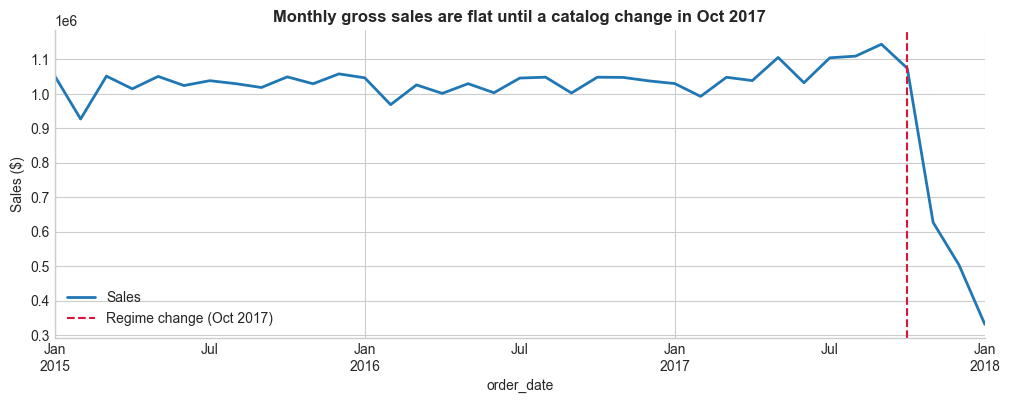

Distinct products  pre: 100 | post: 31
Customers in post period never seen before: 97.3%


In [8]:
monthly = df.groupby(df["order_date"].dt.to_period("M"))["Sales"].sum()
fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax, lw=2)
ax.axvline(pd.Period("2017-10", "M"), color="crimson", ls="--", label="Regime change (Oct 2017)")
ax.set_title("Monthly gross sales are flat until a catalog change in Oct 2017")
ax.set_ylabel("Sales ($)"); ax.legend(); plt.show()

pre, post = df[~df.post_shift], df[df.post_shift]
print("Distinct products  pre:", pre["Product Name"].nunique(), "| post:", post["Product Name"].nunique())
print("Customers in post period never seen before:",
      f"{(~post['customer_id'].isin(pre['customer_id'])).mean():.1%}")

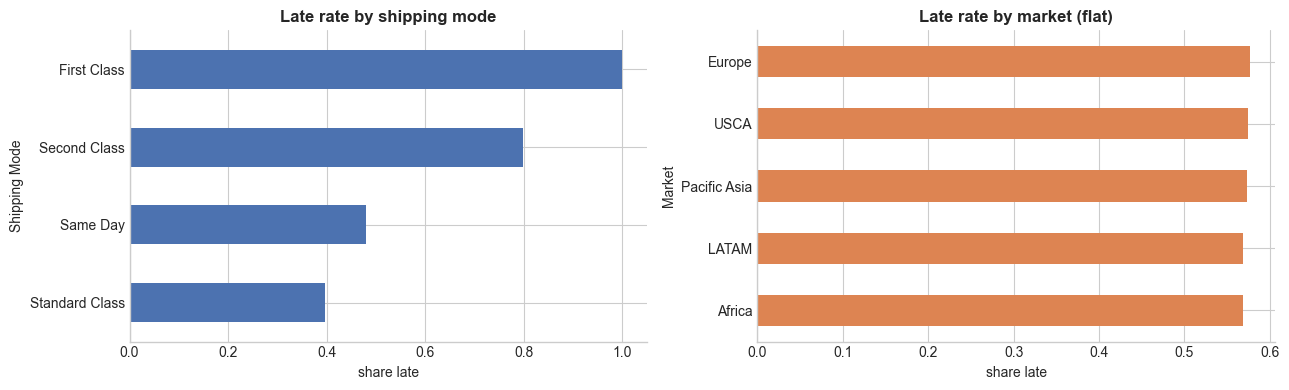

Days for shipping (real)     0     1      2      3      4      5      6
Shipping Mode                                                          
First Class                  0     0  27814      0      0      0      0
Same Day                  5080  4657      0      0      0      0      0
Second Class                 0     0   7138   7065   6978   7052   6983
Standard Class               0     0  21666  21700  21535  21111  21740

Label vs Delivery Status (perfect leakage):
late                   0      1
Delivery Status                
Advance shipping   41592      0
Late delivery          0  98977
Shipping canceled   7754      0
Shipping on time   32196      0


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
notcanc = df[df["Delivery Status"] != "Shipping canceled"]
(notcanc.groupby("Shipping Mode")["late"].mean().sort_values()
        .plot.barh(ax=axes[0], color="#4C72B0"))
axes[0].set_title("Late rate by shipping mode"); axes[0].set_xlabel("share late")
(notcanc.groupby("Market")["late"].mean().sort_values()
        .plot.barh(ax=axes[1], color="#DD8452"))
axes[1].set_title("Late rate by market (flat)"); axes[1].set_xlabel("share late")
plt.tight_layout(); plt.show()

print(pd.crosstab(df["Shipping Mode"], df["Days for shipping (real)"]))
print("\nLabel vs Delivery Status (perfect leakage):")
print(pd.crosstab(df["Delivery Status"], df["late"]))

## 4. Late-delivery prediction

**Design decisions**

- **Grain = order, not line item.** Every item in an order shares the same shipping mode and the same label, so item-level rows are near-duplicates. Training on them inflates the sample size and lets items of one order leak across splits.
- **Exclude canceled orders.** They are labeled 0 by construction (`Shipping canceled`), not because they arrived on time.
- **Only features known at order time.** These are dropped as leakage: `Delivery Status`, `Days for shipping (real)`, `ship_date`, and `Order Status` (it reflects later processing).
- **Time-based split.** Train on Jan 2015–Sep 2016, validate on Oct 2016–Mar 2017, test on Apr–Sep 2017. Post-Oct-2017 orders are kept as a separate **shift test**.

In [10]:
model_df = df[df["Delivery Status"] != "Shipping canceled"].copy()

# The label and order-level attributes are constant within an order — verify, then aggregate.
const_cols = ["late", "Shipping Mode", "Type", "Market", "Order Region", "Customer Segment"]
assert (model_df.groupby("order_id")[const_cols].nunique() == 1).all().all()

orders = (model_df.sort_values("Sales", ascending=False)
          .groupby("order_id")
          .agg(order_date=("order_date", "first"),
               late=("late", "first"),
               shipping_mode=("Shipping Mode", "first"),
               scheduled_days=("Days for shipment (scheduled)", "first"),
               payment_type=("Type", "first"),
               market=("Market", "first"),
               order_region=("Order Region", "first"),
               order_country=("Order Country", "first"),
               customer_segment=("Customer Segment", "first"),
               main_department=("Department Name", "first"),    # dept of highest-value line
               n_items=("order_item_id", "count"),
               n_departments=("Department Name", "nunique"),
               total_qty=("Order Item Quantity", "sum"),
               gross_sales=("Sales", "sum"),
               avg_discount_rate=("Order Item Discount Rate", "mean"),
               max_unit_price=("Order Item Product Price", "max"),
               post_shift=("post_shift", "first"))
          .reset_index())

orders["order_month"] = orders["order_date"].dt.month
orders["order_dow"]   = orders["order_date"].dt.dayofweek
orders["order_hour"]  = orders["order_date"].dt.hour
print(orders.shape, "| late rate:", round(orders["late"].mean(), 3))
orders.head()

(62897, 21) | late rate: 0.573


,order_id,order_date,late,shipping_mode,scheduled_days,payment_type,market,order_region,order_country,customer_segment,main_department,n_items,n_departments,total_qty,gross_sales,avg_discount_rate,max_unit_price,post_shift,order_month,order_dow,order_hour
0,1,2015-01-01 00:00:00,0,Standard Class,4,CASH,LATAM,Central America,México,Consumer,Fan Shop,1,1,1,299.980011,0.200000,299.980011,False,1,3,0
1,2,2015-01-01 00:21:00,0,Standard Class,4,PAYMENT,LATAM,South America,Colombia,Consumer,Golf,3,3,7,579.980011,0.096667,199.990005,False,1,3,0
2,4,2015-01-01 01:03:00,1,Standard Class,4,CASH,LATAM,South America,Colombia,Home Office,Apparel,4,4,14,699.850010,0.142500,59.990002,False,1,3,1
3,5,2015-01-01 01:24:00,1,Standard Class,4,DEBIT,LATAM,South America,Colombia,Consumer,Fan Shop,5,2,10,1129.860039,0.136000,299.980011,False,1,3,1
4,7,2015-01-01 02:06:00,1,Second Class,2,DEBIT,LATAM,South America,Brasil,Consumer,Fan Shop,3,2,7,579.920013,0.070000,299.980011,False,1,3,2


In [11]:
CAT_FEATURES = ["shipping_mode", "payment_type", "market", "order_region", "order_country",
                "customer_segment", "main_department"]
NUM_FEATURES = ["scheduled_days", "n_items", "n_departments", "total_qty", "gross_sales",
                "avg_discount_rate", "max_unit_price", "order_month", "order_dow", "order_hour"]
FEATURES, TARGET = CAT_FEATURES + NUM_FEATURES, "late"

d = orders["order_date"]
train = orders[d < "2016-10-01"]
val   = orders[(d >= "2016-10-01") & (d < "2017-04-01")]
test  = orders[(d >= "2017-04-01") & (d < "2017-10-01")]
shift = orders[orders["post_shift"]]
for name, part in [("train", train), ("val", val), ("test", test), ("shift", shift)]:
    print(f"{name:5} {len(part):6,} orders  {part.order_date.min().date()} -> {part.order_date.max().date()}"
          f"  late={part.late.mean():.3f}")

def evaluate(name, y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {"model": name, "accuracy": accuracy_score(y, yhat), "roc_auc": roc_auc_score(y, p),
            "f1": f1_score(y, yhat), "brier": brier_score_loss(y, p),
            "log_loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6))}

results = []

train 34,918 orders  2015-01-01 -> 2016-09-30  late=0.574
val    9,965 orders  2016-10-01 -> 2017-03-31  late=0.572
test   9,971 orders  2017-04-01 -> 2017-09-30  late=0.570
shift  8,043 orders  2017-10-01 -> 2018-01-31  late=0.576


### 4.1 Baseline 0 — shipping-mode lookup (late rate per mode from training data)

In [12]:
mode_rate = train.groupby("shipping_mode")["late"].mean()
print(mode_rate.round(3))
p_rule = test["shipping_mode"].map(mode_rate).values
results.append(evaluate("Rule: late rate by shipping mode", test[TARGET], p_rule))
pd.DataFrame(results).round(4)

shipping_mode
First Class       1.000
Same Day          0.463
Second Class      0.801
Standard Class    0.400
Name: late, dtype: float64


,model,accuracy,roc_auc,f1,brier,log_loss
0,Rule: late rate by shipping mode,0.6956,0.7419,0.6673,0.1888,0.5394


### 4.2 Baseline 1 — Logistic Regression

In [13]:
logreg = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES)])),
    ("clf", LogisticRegression(max_iter=2000, C=1.0)),
])

# Tune C on the validation set
best_C, best_auc = None, -1
for C in [0.01, 0.1, 1.0, 10.0]:
    logreg.set_params(clf__C=C).fit(train[FEATURES], train[TARGET])
    auc = roc_auc_score(val[TARGET], logreg.predict_proba(val[FEATURES])[:, 1])
    print(f"C={C:<5} val AUC={auc:.4f}")
    if auc > best_auc: best_C, best_auc = C, auc

# Refit on train+val, evaluate once on test
trval = pd.concat([train, val])
logreg.set_params(clf__C=best_C).fit(trval[FEATURES], trval[TARGET])
p_lr = logreg.predict_proba(test[FEATURES])[:, 1]
results.append(evaluate(f"Logistic Regression (C={best_C})", test[TARGET], p_lr))
pd.DataFrame(results).round(4)

C=0.01  val AUC=0.7433
C=0.1   val AUC=0.7479
C=1.0   val AUC=0.7482
C=10.0  val AUC=0.7477


,model,accuracy,roc_auc,f1,brier,log_loss
0,Rule: late rate by shipping mode,0.6956,0.7419,0.6673,0.1888,0.5394
1,Logistic Regression (C=1.0),0.7076,0.7496,0.6861,0.1882,0.5386


### 4.3 Gradient-boosted trees

Uses LightGBM when it is installed (`pip install lightgbm`). Otherwise it falls back to scikit-learn's `HistGradientBoostingClassifier`. Both handle categorical features natively, so no one-hot encoding is needed.

In [14]:
def to_gbt_frame(X, categories=None):
    X = X.copy()
    for c in CAT_FEATURES:
        X[c] = pd.Categorical(X[c], categories=None if categories is None else categories[c])
    return X

cat_levels = {c: sorted(orders[c].unique()) for c in CAT_FEATURES}
Xtr, Xva, Xte, Xsh = (to_gbt_frame(p[FEATURES], cat_levels) for p in (train, val, test, shift))
Xtrval = to_gbt_frame(trval[FEATURES], cat_levels)

def make_gbt(lr, leaves, n_estimators=400):
    if HAS_LGBM:
        return lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=lr, num_leaves=leaves,
                                  min_child_samples=50, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, random_state=RANDOM_STATE, verbose=-1)
    return HistGradientBoostingClassifier(max_iter=n_estimators, learning_rate=lr, max_leaf_nodes=leaves,
                                          min_samples_leaf=50, categorical_features="from_dtype",
                                          early_stopping=False, random_state=RANDOM_STATE)

# Small grid on the validation set (keep it small — there is little signal to find)
grid = [(lr, leaves, n) for lr in (0.03, 0.1) for leaves in (15, 31) for n in (200, 500)]
scores = []
for lr, leaves, n in grid:
    m = make_gbt(lr, leaves, n).fit(Xtr, train[TARGET])
    scores.append((roc_auc_score(val[TARGET], m.predict_proba(Xva)[:, 1]), lr, leaves, n))
scores.sort(reverse=True)
print(pd.DataFrame(scores, columns=["val_auc", "lr", "leaves", "n_estimators"]).round(4))

_, lr, leaves, n = scores[0]
gbt = make_gbt(lr, leaves, n).fit(Xtrval, trval[TARGET])
p_gbt = gbt.predict_proba(Xte)[:, 1]
gbt_name = ("LightGBM" if HAS_LGBM else "HistGradientBoosting") + f" (lr={lr}, leaves={leaves}, n={n})"
results.append(evaluate(gbt_name, test[TARGET], p_gbt))
res = pd.DataFrame(results).round(4)
res

   val_auc    lr  leaves  n_estimators
0   0.7801  0.03      15           500
1   0.7787  0.03      15           200
2   0.7777  0.03      31           500
3   0.7774  0.03      31           200
4   0.7754  0.10      15           200
5   0.7750  0.10      15           500
6   0.7736  0.10      31           200
7   0.7692  0.10      31           500


,model,accuracy,roc_auc,f1,brier,log_loss
0,Rule: late rate by shipping mode,0.6956,0.7419,0.6673,0.1888,0.5394
1,Logistic Regression (C=1.0),0.7076,0.7496,0.6861,0.1882,0.5386
2,"LightGBM (lr=0.03, leaves=15, n=500)",0.7231,0.7756,0.7090,0.1762,0.5067


### 4.4 Diagnostics — confusion matrices, calibration, feature importance

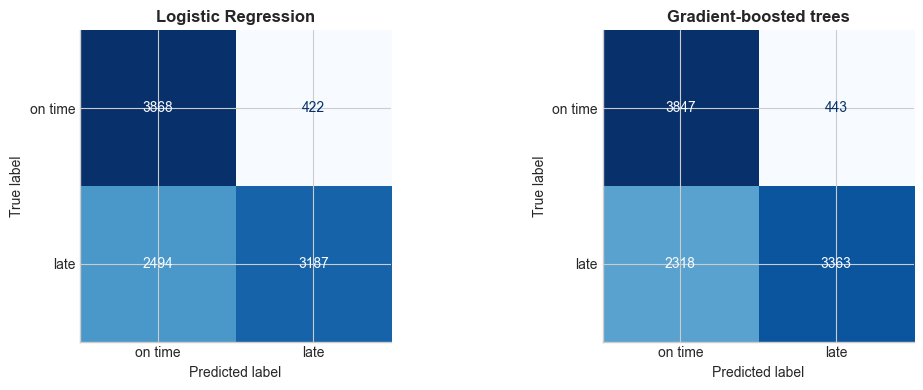

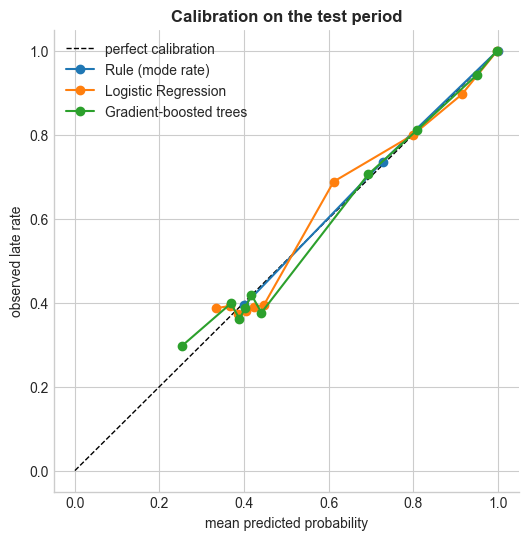

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, p) in zip(axes, [("Logistic Regression", p_lr), ("Gradient-boosted trees", p_gbt)]):
    ConfusionMatrixDisplay(confusion_matrix(test[TARGET], (p >= 0.5).astype(int)),
                           display_labels=["on time", "late"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

# Reliability diagram: are predicted probabilities trustworthy?
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
for name, p in [("Rule (mode rate)", p_rule), ("Logistic Regression", p_lr), ("Gradient-boosted trees", p_gbt)]:
    frac_pos, mean_pred = calibration_curve(test[TARGET], p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, "o-", label=name)
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed late rate")
ax.set_title("Calibration on the test period"); ax.legend(); plt.show()

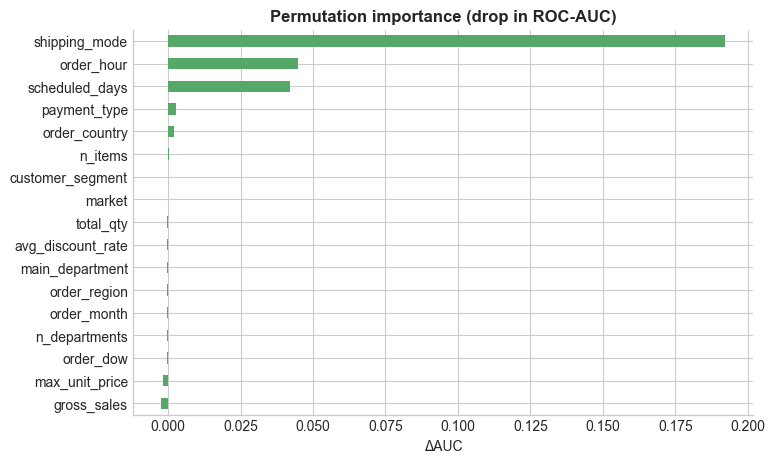

In [16]:
# Permutation importance (model-agnostic, measured on the test set)
sub = test.sample(min(len(test), 5000), random_state=RANDOM_STATE)
pi = permutation_importance(gbt, to_gbt_frame(sub[FEATURES], cat_levels), sub[TARGET],
                            scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(color="#55A868", figsize=(8, 5))
plt.title("Permutation importance (drop in ROC-AUC)"); plt.xlabel("ΔAUC"); plt.show()

### 4.5 Robustness checks

- **Distribution shift.** How do the models perform on the post-Oct-2017 regime (new catalog, new customers)?
- **Leakage demonstration.** What happens when `Days for shipping (real)` is added back? Many public notebooks report 97–99% accuracy, and this is why.

In [17]:
shift_rows = [
    evaluate("Rule (shift)", shift[TARGET], shift["shipping_mode"].map(mode_rate).values),
    evaluate("Logistic Regression (shift)", shift[TARGET], logreg.predict_proba(shift[FEATURES])[:, 1]),
    evaluate("Gradient-boosted trees (shift)", shift[TARGET], gbt.predict_proba(Xsh)[:, 1]),
]
display(pd.DataFrame(shift_rows).round(4))

# Leakage demo: add the realised shipping duration
real_days = model_df.groupby("order_id")["Days for shipping (real)"].first()
leaky_feats = FEATURES + ["real_days"]
tv, te = trval.assign(real_days=trval.order_id.map(real_days)), test.assign(real_days=test.order_id.map(real_days))
leaky = Pipeline([
    ("prep", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CAT_FEATURES),
        ("num", StandardScaler(), NUM_FEATURES + ["real_days"])])),
    ("clf", LogisticRegression(max_iter=2000)),
]).fit(tv[leaky_feats], tv[TARGET])
p_leak = leaky.predict_proba(te[leaky_feats])[:, 1]
display(pd.DataFrame([evaluate("LogReg + LEAKED real shipping days", te[TARGET], p_leak)]).round(4))

,model,accuracy,roc_auc,f1,brier,log_loss
0,Rule (shift),0.696,0.7447,0.6719,0.1876,0.5359
1,Logistic Regression (shift),0.706,0.7534,0.6872,0.1869,0.5351
2,Gradient-boosted trees (shift),0.720,0.7804,0.7149,0.1750,0.5032


,model,accuracy,roc_auc,f1,brier,log_loss
0,LogReg + LEAKED real shipping days,1.0,1.0,1.0,0.0,0.002


**Reading the results.** On honest, order-time features, every model stays close to the shipping-mode rule (about 70% accuracy). Gradient boosting gains only a few points of AUC, because realised shipping time is close to uniformly random within each mode in this (most likely simulated) dataset. Check the permutation importance to see where the extra signal comes from. A modest gap is the expected, *honest* outcome. Adding the realised shipping days pushes accuracy toward 100%, which is leakage, not skill.

## 5. Customer segmentation — RFM + K-means

- **Valid purchases only.** `CANCELED` and `SUSPECTED_FRAUD` orders are excluded.
- **Window: Jan 2015–Sep 2017.** About 97% of post-Oct-2017 customers are brand new. Including them would create an artificial "recent one-timer" cluster driven by the regime change rather than by behaviour.
- **Features.** Recency is days since the last order (relative to the snapshot date), Frequency is the number of distinct orders, and Monetary is net spend (`Order Item Total`).

Snapshot date: 2017-10-01 | customers: 12296


,recency,frequency,monetary
count,12296.0,12296.0,12296.0
mean,214.6,4.5,2396.2
std,196.6,2.1,1281.0
min,1.0,1.0,24.2
25%,65.0,3.0,1453.5
50%,156.0,4.0,2235.2
75%,305.0,6.0,3172.7
max,1003.0,14.0,9436.6


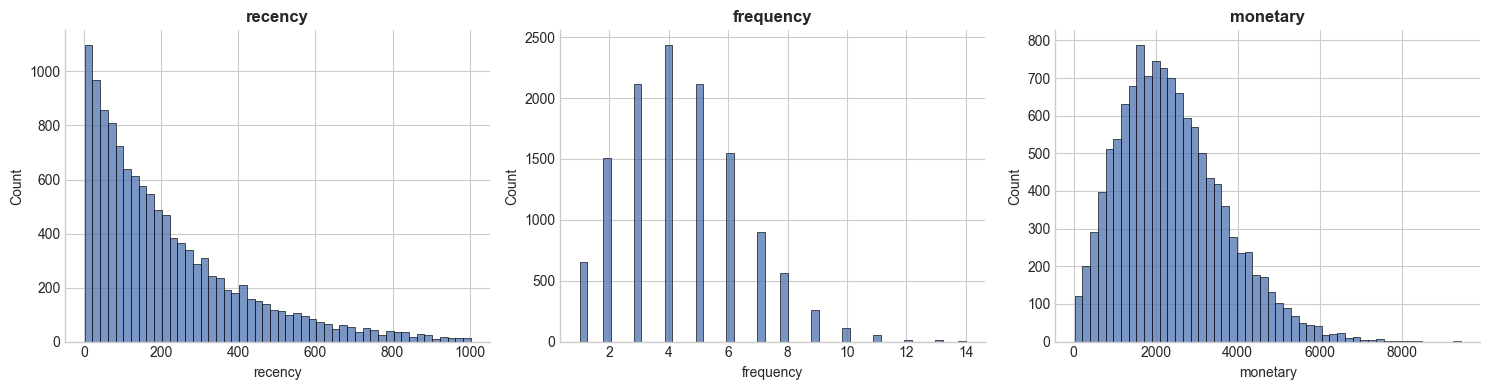

In [18]:
rfm_src = df[(~df["Order Status"].isin(["CANCELED", "SUSPECTED_FRAUD"])) & (~df["post_shift"])]
snapshot = rfm_src["order_date"].max() + pd.Timedelta(days=1)

rfm = (rfm_src.groupby("customer_id")
       .agg(recency=("order_date", lambda s: (snapshot - s.max()).days),
            frequency=("order_id", "nunique"),
            monetary=("Order Item Total", "sum"),
            segment=("Customer Segment", "first"))
       .reset_index())
print("Snapshot date:", snapshot.date(), "| customers:", len(rfm))
display(rfm[["recency", "frequency", "monetary"]].describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["recency", "frequency", "monetary"]):
    sns.histplot(rfm[c], bins=50, ax=ax, color="#4C72B0"); ax.set_title(c)
plt.tight_layout(); plt.show()

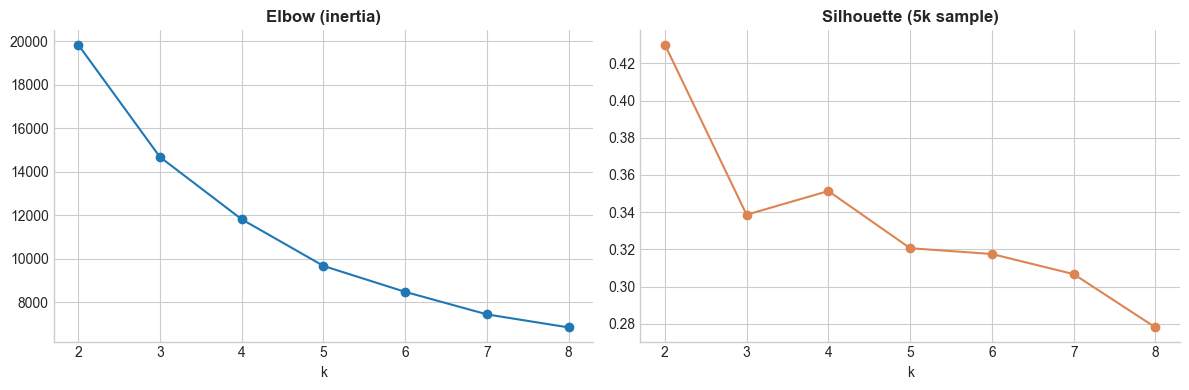

   k    inertia  silhouette
0  2  19854.971       0.430
1  3  14684.307       0.339
2  4  11817.602       0.351
3  5   9671.837       0.321
4  6   8478.250       0.317
5  7   7442.571       0.307
6  8   6842.370       0.278


In [19]:
# Frequency and Monetary are right-skewed -> log1p, then standardise all three
X_rfm = np.column_stack([rfm["recency"], np.log1p(rfm["frequency"]), np.log1p(rfm["monetary"])])
X_rfm = StandardScaler().fit_transform(X_rfm)

ks, inertias, sils = range(2, 9), [], []
rng = np.random.default_rng(RANDOM_STATE)
sample_idx = rng.choice(len(X_rfm), size=min(5000, len(X_rfm)), replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_rfm)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_rfm[sample_idx], km.labels_[sample_idx]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, "o-"); axes[0].set_title("Elbow (inertia)"); axes[0].set_xlabel("k")
axes[1].plot(list(ks), sils, "o-", color="#DD8452"); axes[1].set_title("Silhouette (5k sample)"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"k": list(ks), "inertia": inertias, "silhouette": sils}).round(3))

In [20]:
# Choose k: highest silhouette among k=3..6 (k=2 usually just splits one-timers vs. the rest,
# which is too coarse to act on). Override K manually if the elbow suggests otherwise.
K = int(pd.Series(sils, index=list(ks)).loc[3:6].idxmax())
print("Chosen k =", K)

kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_rfm)
rfm["cluster"] = kmeans.labels_

profile = (rfm.groupby("cluster")
           .agg(customers=("customer_id", "count"),
                recency_days=("recency", "median"),
                orders=("frequency", "median"),
                spend=("monetary", "median"),
                total_spend=("monetary", "sum"))
           .assign(customer_share=lambda t: t.customers / t.customers.sum(),
                   revenue_share=lambda t: t.total_spend / t.total_spend.sum()))

# Name clusters relative to each other: recent vs lapsed (cluster recency vs the median
# across clusters) x higher vs lower value (cluster spend vs the median across clusters)
rec_med, val_med = profile["recency_days"].median(), profile["spend"].median()
def name_cluster(row):
    recent = row["recency_days"] <= rec_med
    high   = row["spend"] >= val_med
    return {(True, True): "Champions", (True, False): "Recent, developing",
            (False, True): "At risk (lapsed high-value)", (False, False): "Hibernating"}[(recent, high)]
profile["label"] = profile.apply(name_cluster, axis=1)
dupes = profile["label"].duplicated(keep=False)                  # disambiguate if k > 4
profile.loc[dupes, "label"] += " #" + profile.index[dupes].astype(str)
label_map = profile["label"].to_dict()
rfm["label"] = rfm["cluster"].map(label_map)
order = profile.sort_values("spend", ascending=False).index
profile.loc[order].round(3)

Chosen k = 4


,customers,recency_days,orders,spend,total_spend,customer_share,revenue_share,label
cluster,,,,,,,,
1,5137,90.0,6.0,3318.74,1.795650e+07,0.418,0.609,Champions
3,2143,391.0,4.0,2084.23,4.670356e+06,0.174,0.159,At risk (lapsed high-value)
0,3669,118.0,3.0,1595.66,5.870530e+06,0.298,0.199,"Recent, developing"
2,1347,521.0,2.0,695.35,9.663592e+05,0.110,0.033,Hibernating


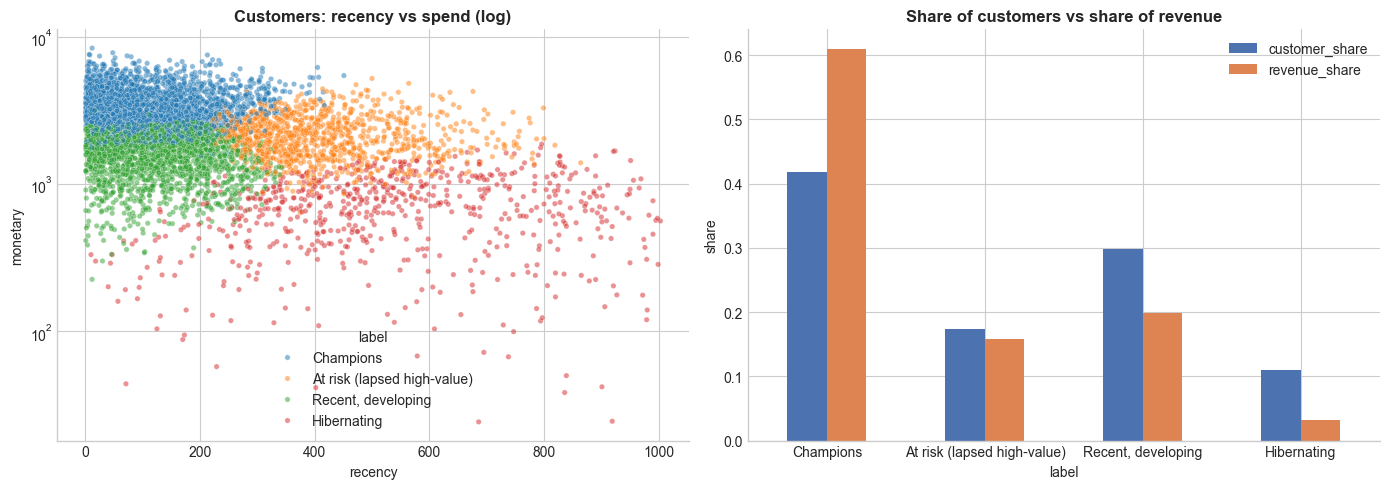

segment,Consumer,Corporate,Home Office
label,,,
At risk (lapsed high-value),0.178,0.171,0.169
Champions,0.417,0.420,0.416
Hibernating,0.114,0.101,0.111
"Recent, developing",0.291,0.308,0.304


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=rfm.sample(min(6000, len(rfm)), random_state=RANDOM_STATE),
                x="recency", y="monetary", hue="label", alpha=0.5, s=15, ax=axes[0])
axes[0].set_yscale("log"); axes[0].set_title("Customers: recency vs spend (log)")

share = profile.loc[order].set_index("label")[["customer_share", "revenue_share"]]
share.plot.bar(ax=axes[1], color=["#4C72B0", "#DD8452"], rot=0)
axes[1].set_title("Share of customers vs share of revenue"); axes[1].set_ylabel("share")
plt.tight_layout(); plt.show()

# Does the business-defined Customer Segment line up with behaviour?
pd.crosstab(rfm["label"], rfm["segment"], normalize="columns").round(3)

## 6. Summary and next steps

**Cleaning.** Dates are repaired and verified against the recorded shipping days. Three column-shifted rows are fixed, and 18 masked, constant, redundant or leaky columns are dropped. A regime flag marks the post-Oct-2017 data.

**Late delivery.** On order-time features only, logistic regression and gradient-boosted trees both perform close to a shipping-mode lookup. Shipping mode dominates the importance plot, and the leakage demo shows why near-perfect scores reported elsewhere are not meaningful. Check the calibration plot to see whether the predicted probabilities can be trusted.

**Segmentation.** RFM + K-means gives behaviourally distinct groups (compare customer share with revenue share). The business `Customer Segment` field barely differs across clusters, so behaviour carries information that the existing segment label does not.

**Possible extensions**
- Post-hoc calibration (temperature/Platt or isotonic on the validation set) and comparison of ECE across models.
- Cost-sensitive thresholds, if a missed late delivery costs more than a false alarm.
- CatBoost / target encoding for `order_country`; SHAP for per-order explanations.
- Demand forecasting per category using the pre-shift window only.